# IMPORTS

In [121]:
import csv 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

np.random.seed(42)

In [122]:
repo_root = os.path.abspath(os.path.join(".."))

save_dir = os.path.join(repo_root, "results", "eda")
os.makedirs(save_dir, exist_ok=True)
print(f"All outputs will be saved under: {save_dir}")

plots_dir = os.path.join(repo_root, "plots", "eda")
os.makedirs(plots_dir, exist_ok=True)
print(f"All plots will be saved under: {plots_dir}")

# Define subdirectory for category plots
plots_categories_dir = os.path.join(plots_dir, "categories")
os.makedirs(plots_categories_dir, exist_ok=True)

All outputs will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda
All plots will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda


In [123]:
def read_csv_numeric(path): 
    # 1) read header for the name→index mapping 
    with open(path, newline='', encoding='utf-8') as f: 
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # If the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [124]:
# emma paths
x_indices, x_data = read_csv_numeric("../dataset/x_train.csv")
y_indices, y_data = read_csv_numeric("../dataset/y_train.csv")

# Reduced feature set

In [173]:
# reduced feature set (after removing high na, duplicates, not interesting etc)
reduced_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTAE1', '_PASTRNG', 'EDUCA', '_RFHLTH', 'CHCCOPD1', 'DRADVISE', 
                        'CHCKIDNY', 'ARTHSOCL', 'SMOKDAY2', '_RFSEAT2', '_MISVEGN', 'WTCHSALT', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 
                        'DIABAGE2', 'VETERAN3', 'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_TOTINDA', '_PACAT1', 
                        'INSULIN', 'DROCDY3_', 'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'MAXDRNKS', '_LMTWRK1', 'RENTHOM1', 'PAMIN11_', 
                        'PADUR2_', 'STOPSMK2', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 'POORHLTH', 'FRUTDA1_', 'DIABETE3', '_FRUTSUM', '_LMTACT1',
                        'PERSDOC2', 'STRFREQ_', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 'DRNK3GE5', 'ALCDAY5', 'BPHIGH4', 'GENHLTH',
                        'EXRACT11', '_FRUITEX', '_BMI5', 'PAVIG11_', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'AVEDRNK2', 'ORNGDAY_', 
                        '_MISFRTN', 'MSCODE', 'PHYSHLTH', 'TOLDHI2', '_SMOKER3', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'WTKG3', 'CHCSCNCR', 
                        'PAFREQ1_', '_AIDTST3', 'FLSHTMY2', 'PA1VIGM_', 'HIVTST6', 'METVL21_', '_PAINDX1', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 
                        'MAXVO2_', 'VEGEDA1_', '_RACE_G1', 'GRENDAY_', '_MINAC11', 'LONGWTCH', 'FC60_', 'PAMISS1_', 'SCNTWRK1', 'FEETCHK2', 
                        'EMPLOY1', 'BLOODCHO', 'USENOW3', 'PAMIN21_', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 'ADDEPEV2', '_AGE80', 
                        'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', '_MINAC21', 'PREDIAB1', 'BPMEDS', '_VEGETEX', 
                        'HAVARTH3', 'PAVIG21_', 'CHECKUP1', 'TRNSGNDR', 'CHILDREN']

In [174]:
# map non available to NA

# 6-digit: DK/Ref codes like 777777 / 999999
six_digit = [
    'FLSHTMY2',
    'HIVTSTD3',
]

# 5-digit: DK/Ref codes like 99999 (e.g., WTKG3)
five_digit = [
    'PA1VIGM_',
    'PAFREQ2_',
    'WTKG3',
]

# 4-digit: DK/Ref codes like 7777 / 9999 (e.g., WEIGHT2)
four_digit = [
    'AVEDRNK2',
    'BEANDAY_',
    'FRUTDA1_',
    'FTJUDA1_',
    'GRENDAY_',
    'HEIGHT3',
    'ORNGDAY_',
    'VEGEDA1_',
    'WEIGHT2',
    '_BMI5',
    '_BMI5CAT',
    '_RFBMI5',
]

# 3-digit: DK/Ref codes like 777 / 999 (e.g., ALCDAY5)
triple_digit = [
    'ALCDAY5',
    'ASACTLIM',
    'ASNOSLEP',
    'BLDSUGAR',
    'CDHELP',
    'DRNK3GE5',
    'DRNKANY5',
    'EXERHMM1',
    'EXERHMM2',
    'EXEROFT1',
    'EXEROFT2',
    'FEETCHK2',
    'FRUIT1',
    'FRUITJU1',
    'FVBEANS',
    'FVGREEN',
    'FVORANG',
    'LONGWTCH',
    'MAXDRNKS',
    'STRENGTH',
    'VEGETAB1',
    '_LMTSCL1',
    '_RFBING5',
]

# 2-digit: DK/Ref codes like 77 / 99 (e.g., DRNK3GE5)
double_digit = [
    'ADANXEV','ADDOWN','ADEAT1','ADENERGY','ADFAIL','ADMOVE','ADPLEASR','ADSLEEP','ADTHINK','ARTHSOCL',
    'ARTTODAY','ASINHALR','ASRCHKUP','ASTHMAGE','CAREGIV1','CASTHDX2','CDDISCUS','CDSOCIAL','CHKHEMO3','CRGVEXPT',
    'CRGVHOUS','CRGVPERS','CRGVPRB1','CRGVREL1','CVDINFR4','DIABAGE2','DIABETE3','DOCTDIAB','EMTSUPRT','EXRACT11',
    'EXRACT21','FC60_','FEETCHK','HAREHAB1','HHADULT','HOWLONG','HPVADVC2','IMFVPLAC','INCOME2','JOINPAIN',
    'LASTSIG3','LASTSMK2','LENGEXAM','LSTBLDS3','MAXVO2_','MENTHLTH','PAFREQ1_','PERSDOC2','PHYSHLTH','POORHLTH',
    'PSATIME','RDUCHART','SCNTLWK1','SCNTWRK1','SXORIENT','TRNSGNDR','VETERAN3','VINOCRE2','WHRTST10','_ASTHMS1',
    '_CRACE1','_DRDXAR1','_EDUCAG','_PNEUMO2','_PRACE1','_RACE','_RACE_G1','_WT2RAKE',
]

# 1-digit: DK/Ref codes like 7 / 9 (e.g., EXERANY2)
single_digit = [
    'ADDEPEV2','ARTHDIS2','ARTHEDU','ARTHEXER','ARTHWGT','ASATTACK','ASDRVIST','ASERVIST','ASPUNSAF','ASTHMA3','ASTHMED3','ASYMPTOM',
    'BLDSTOOL','BLIND','BLOODCHO','BPHIGH4','CASTHNO2','CDASSIST','CDHOUSE','CHCCOPD1','CHCKIDNY','CHECKUP1','CHOLCHK','CIMEMLOS',
    'CPDEMO1','CRGVHRS1','CRGVMST2','DECIDE','DIABEDU','DIABEYE','DIFFALON','DRADVISE','EDUCA','EXERANY2','EYEEXAM','FLUSHOT6',
    'HADHYST2','HADMAM','HADPAP2','HADSGCO1','HADSIGM3','HAVARTH3','HIVTST6','HLTHPLN1','HPVADSHT','HPVTEST','LANDLINE','LMTJOIN3',
    'MEDCOST','MISTMNT','NUMHHOL2','PCPSAAD2','PCPSADE1','PCPSADI1','PCPSARE1','PDIABTST','PNEUVAC3','PREDIAB1','PROFEXAM','QLACTLM2',
    'RENTHOM1','SCNTLPAD','SCNTMEL1','SCNTMNY1','SCNTPAID','SEATBELT','SMOKE100','STOPSMK2','STREHAB1','STRFREQ_','TETANUS','TOLDHI2',
    'USEEQUIP','USENOW3','VICTRCT4','VIDFCLT2','VIEYEXM2','VIGLUMA2','VIMACDG2','VIPRFVS2','VIREDIF3','WTCHSALT','_CHOLCHK','_HCVU651',
    '_LLCPWT','_LMTACT1','_MICHD','_PA150R2','_PA30021','_PA300R2','_PASTRNG','_RACEG21','_RFCHOL','_RFDRHV5','_RFHYPE5','_RFSEAT2',
    '_SMOKER3','_TOTINDA','_VEGESUM',
]

# No explicit DK/Ref "7…/9…" code in that variable’s own table
no_dk_rf = [
    'ACTIN11_','ACTIN21_','ASTHNOW','BPMEDS','CADULT','CCLGHOUS','CELLFON2','CELLFON3','CHCOCNCR','CHCSCNCR',
    'CHILDREN','COLGHOUS','CRGVLNG1','CSTATE','CTELENUM','CTELNUM1','CVDASPRN','CVDCRHD4','CVDSTRK3','DIFFDRES',
    'DIFFWALK','DISPCODE','DROCDY3_','EMPLOY1','EXACTOT1','EXACTOT2','EXRACT11','EXRACT21','FMONTH','GENHLTH',
    'HPLSTTST','HTIN4','HTM4','IDATE','IDAY','IMONTH','INSULIN','INTERNET','IYEAR','LADULT',
    'LASTPAP2','LSATISFY','MARITAL','METVL11_','METVL21_','MSCODE','NUMADULT','NUMMEN','NUMPHON2','NUMWOMEN',
    'PA1MIN_','PADUR1_','PADUR2_','PAINACT2','PAMIN11_','PAMIN21_','PAMISS1_','PAVIG11_','PAVIG21_','PCDMDECN',
    'PCPSARS1','PREGNANT','PSATEST1','PVTRESD1','PVTRESD2','QLHLTH2','QLMENTL2','QLSTRES2','QSTLANG','QSTVER',
    'RCSGENDR','RCSRLTN2','RDUCSTRK','RLIVPAIN','SEQNO','SEX','SHINGLE2','SMOKDAY2','STATERES','VIINSUR2',
    '_AGE65YR','_AGE80','_AGEG5YR','_AGE_G','_AIDTST3','_CASTHM1','_CHISPNC','_CHLDCNT','_CLLCPWT','_CPRACE',
    '_DRNKWEK','_DUALCOR','_DUALUSE','_FLSHOT6','_FRT16','_FRTLT1','_FRTRESP','_FRUITEX','_FRUTSUM','_HISPANC',
    '_INCOMG','_LMTWRK1','_LTASTH1','_MINAC11','_MINAC21','_MISFRTN','_MISVEGN','_MRACE1','_PACAT1','_PAINDX1',
    '_PAREC1','_PASTAE1','_PSU','_RACEGR3','_RAWRAKE','_RFHLTH','_RFSEAT3','_RFSMOK3','_STATE','_STRWT',
    '_STSTR','_VEG23','_VEGETEX','_VEGLT1','_VEGRESP',
]


for c in reduced_feature_set:
    if c in single_digit:
        x_data[x_data[:, x_indices[c]] == 7, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9, x_indices[c]] = np.nan
    elif c in double_digit:
        x_data[x_data[:, x_indices[c]] == 77, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99, x_indices[c]] = np.nan
    elif c in triple_digit:
        x_data[x_data[:, x_indices[c]] == 777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999, x_indices[c]] = np.nan
    elif c in four_digit:
        x_data[x_data[:, x_indices[c]] == 7777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9999, x_indices[c]] = np.nan
    elif c in five_digit:
        x_data[x_data[:, x_indices[c]] == 77777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99999, x_indices[c]] = np.nan
    elif c in six_digit:
        x_data[x_data[:, x_indices[c]] == 777777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999999, x_indices[c]] = np.nan
    else:
        if c not in no_dk_rf: 
            raise Exception("Not in any group", c)
    
x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] * 0.453592
x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] - 9000
x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]] = ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) // 100) * 30.48 + ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) % 100) * 2.54
x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] = x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] - 9000
x_data[x_data[:, x_indices["WEIGHT2"]] > 200, x_indices["WEIGHT2"]] = np.nan


In [175]:
reduced_set_idx = [x_indices[name] for name in reduced_feature_set]
x_train_reduced = x_data[:, reduced_set_idx]
x_indices_reduced = {name: i for i, name in enumerate(reduced_feature_set)} # new ids in reduced set

In [176]:
print(f"Reduced X shape: {x_train_reduced.shape}")
print(f"Features kept: {len(reduced_feature_set)}")

Reduced X shape: (328135, 122)
Features kept: 122


# Categories of variables

In [177]:
categories = [
    "demographics_socioeconomic",
    "body_measures",
    "health_status",
    "chronic_conditions",
    "lifestyle_behaviors",
    "physical_activity",
    "diet_nutrition",
    "access_to_care"
]

In [178]:
demographics_socioeconomic = [
    "SEX",          # respondent sex
    "_AGE80",       # age
    "INCOME2",      # income category
    "EDUCA",        # education level
    "EMPLOY1",      # employment status
    "MARITAL",      # marital status
    "CHILDREN",     # number of children
    "VETERAN3",     # veteran status
    "_MRACE1",      # race category
    "_RACE_G1",     # race group
    "TRNSGNDR",     # transgender identity
    "SXORIENT",     # sexual orientation
    "MSCODE",       # metropolitan status code
    "RENTHOM1",     # home ownership
]


In [179]:
body_measures = [
    "HTM4",      # height in meters
    "WTKG3",     # weight in kilograms
    "_BMI5",     # body mass index (BMI * 100)
]


In [180]:
health_status = [
    "GENHLTH",     # general health perception
    "PHYSHLTH",    # number of physically unhealthy days
    "MENTHLTH",    # number of mentally unhealthy days
    "POORHLTH",    # total days with poor physical/mental health
    "_RFHLTH",     # calculated: good or poor health
    "_LMTACT1",    # limited activity due to health
    "_LMTSCL1",    # limited in social activities due to health
    "_LMTWRK1",    # limited in work activities due to health
    "QLACTLM2",    # limited in any activities because of health
    "DECIDE",      # difficulty concentrating, remembering, making decisions
    "DIFFALON",    # difficulty walking or climbing stairs
    "DIFFWALK",    # difficulty walking (duplicate context)
    "DIFFDRES",    # difficulty dressing/bathing
    "USEEQUIP",    # need special equipment for health condition
]


In [181]:
chronic_conditions = [
    "_ASTHMS1",   # ever told had asthma (lifetime)
    "_CASTHM1",   # currently has asthma
    "CHCCOPD1",   # ever told had COPD
    "CHCKIDNY",   # ever told had kidney disease
    "CHCSCNCR",   # ever told had skin cancer
    "CHCOCNCR",   # ever told had any other type of cancer
    "CVDSTRK3",   # ever told had a stroke
    "DIABETE3",   # ever told had diabetes
    "PREDIAB1",   # ever told had prediabetes or borderline diabetes
    "DOCTDIAB",   # doctor visits for diabetes
    "DIABAGE2",   # age when diagnosed with diabetes
    "INSULIN",    # currently taking insulin
    "FEETCHK",    # number of times feet checked (diabetes-related)
    "FEETCHK2",   # diabetes foot check (follow-up variant)
    "BPHIGH4",    # ever told had high blood pressure
    "BPMEDS",     # currently taking medication for HBP
    "TOLDHI2",    # ever told had high cholesterol
    "BLOODCHO",   # taking cholesterol-lowering medication
    "ARTHDIS2",   # doctor-diagnosed arthritis
    "HAVARTH3",   # ever told had arthritis
    "ARTHSOCL",   # arthritis affecting social activities
    "LMTJOIN3",   # arthritis affecting joints
    "JOINPAIN",   # current joint pain from arthritis
    "BLIND",      # blindness or serious vision difficulty
    "ADDEPEV2",   # ever told had depressive disorder
]


In [182]:
lifestyle_behaviors = [
    # --- Smoking ---
    "SMOKE100",    # ever smoked 100 cigarettes
    "SMOKDAY2",    # current smoking frequency
    "STOPSMK2",    # tried to quit smoking
    "USENOW3",     # current tobacco use (e-cigarettes or smokeless)
    "_SMOKER3",    # derived: overall smoking status (current/former/never)

    # --- Alcohol ---
    "DRNKANY5",    # had any alcoholic drinks in past 30 days
    "ALCDAY5",     # drinking frequency
    "AVEDRNK2",    # average drinks per day
    "DRNK3GE5",    # binge drinking frequency (≥5 drinks)
    "MAXDRNKS",    # maximum drinks on one occasion
    "_DRNKWEK",    # computed drinks per week

    # --- Diet / Salt / Food choices ---
    "WTCHSALT",    # trying to reduce salt intake
    "LONGWTCH",    # trying to lose weight or maintain weight
    "_MISVEGN",    # missing vegetable data (proxy for diet quality)
    "_MISFRTN",    # missing fruit data

    "_RFSEAT2",    # seatbelt or not
]


In [183]:
physical_activity = [
    "EXERANY2",    # participated in any physical activities during past month
    "_TOTINDA",    # derived: total physical activity level
    "_PACAT1",     # physical activity category (active / insufficient / inactive)
    "_PAINDX1",    # physical activity index based on intensity and frequency
    "_PAREC1",     # recreational physical activity index

    # --- Activity sessions and metrics ---
    "PA1MIN_",     # minutes per week of vigorous activity
    "PA1VIGM_",    # vigorous activity minutes per session
    "PAVIG11_",    # vigorous activity per week (MET value)
    "PAVIG21_",    # vigorous activity (alt category)
    "PAMIN11_",    # minutes per week of moderate activity
    "PAMIN21_",    # same, alt category
    "PAFREQ1_",    # frequency of vigorous activity
    "PAFREQ2_",    # frequency of moderate activity
    "PADUR1_",     # duration of vigorous activity
    "PADUR2_",     # duration of moderate activity
    "PAMISS1_",    # missing activity data indicator
    "_PASTAE1",    # sedentary time (from physical activity question)
    "_PASTRNG",    # strength training participation
    "EXRACT11",    # extra activity measure 1 (derived)
    "EXRACT21",    # extra activity measure 2 (derived)
    "PAMIN11_",    # minutes of moderate activity
    "METVL11_",    # MET value (vigorous)
    "METVL21_",    # MET value (moderate)
    "MAXVO2_",     # estimated VO₂ max
    "FC60_",       # fitness capacity index (60s test)
    "_MINAC11",    # minimal activity (vigorous)
    "_MINAC21",    # minimal activity (moderate)
    "SCNTWRK1",    # physically demanding job (standing/walking)
    "STRFREQ_",    # how often strength training
]


In [184]:
diet_nutrition = [
    "FRUIT1",      # consumed fruit 1+ times per day
    "FRUTDA1_",    # average daily fruit intake (times/day)
    "_FRUTSUM",    # total fruit consumption summary variable
    "VEGEDA1_",    # average daily vegetable intake (times/day)
    "_VEGESUM",    # total vegetable consumption summary variable
    "_FRUITEX",    # derived fruit intake index (expanded)
    "_VEGETEX",    # derived vegetable intake index (expanded)
    "ORNGDAY_",    # average orange or juice intake (times/day)
    "BEANDAY_",    # average bean intake (times/day)
    "GRENDAY_",    # average green salad intake (times/day)
    "DROCDY3_",    # number drinks of sugar-sweetened beverages (non-alcoholic) consumed per day
]
diet_nutrition.append("DROCDY3_")
lifestyle_behaviors.append("_RFSEAT2")
physical_activity.append("STRFREQ_")
demographics_socioeconomic.append("RENTHOM1")


In [185]:
access_to_care = [
    "CHECKUP1",    # time since last routine checkup
    "CHOLCHK",     # cholesterol check in past 5 years
    "BLOODCHO",    # currently taking cholesterol medication
    "DRADVISE",    # doctor gave advice about exercise or diet
    "PERSDOC2",    # has a personal doctor or healthcare provider
    "MEDCOST",     # couldn’t see doctor due to cost
    "FEETCHK",     # number of times feet checked for diabetes
    "FEETCHK2",    # follow-up foot check variable
    "DOCTDIAB",    # doctor visits for diabetes
    "CHKHEMO3",    # blood test for hemoglobin A1C
    "INSULIN",     # insulin use (diabetes treatment access)
    "FLUSHOT6",    # flu shot in past 12 months
    "FLSHTMY2",    # month/year of last flu shot
    "PNEUVAC3",    # pneumonia vaccination
    "HIVTST6",     # ever tested for HIV
    "_AIDTST3",    # AIDS test status
]


In [186]:
# check if all categories sum up to reduced_features
all_categorized = (
    demographics_socioeconomic
    + body_measures
    + health_status
    + chronic_conditions
    + lifestyle_behaviors
    + physical_activity
    + diet_nutrition
    + access_to_care
)

set_all, set_reduced = set(all_categorized), set(reduced_feature_set)

if set_all == set_reduced:
    print("Perfect match.")
else:
    print("Missing:", set_reduced - set_all)
    print("Extra:", set_all - set_reduced)


Perfect match.


In [187]:
feature_clusters = {
    "demographics_socioeconomic": demographics_socioeconomic,
    "body_measures": body_measures,
    "health_status": health_status,
    "chronic_conditions": chronic_conditions,
    "lifestyle_behaviors": lifestyle_behaviors,
    "physical_activity": physical_activity,
    "diet_nutrition": diet_nutrition,
    "access_to_care": access_to_care
}


# Per category analysis

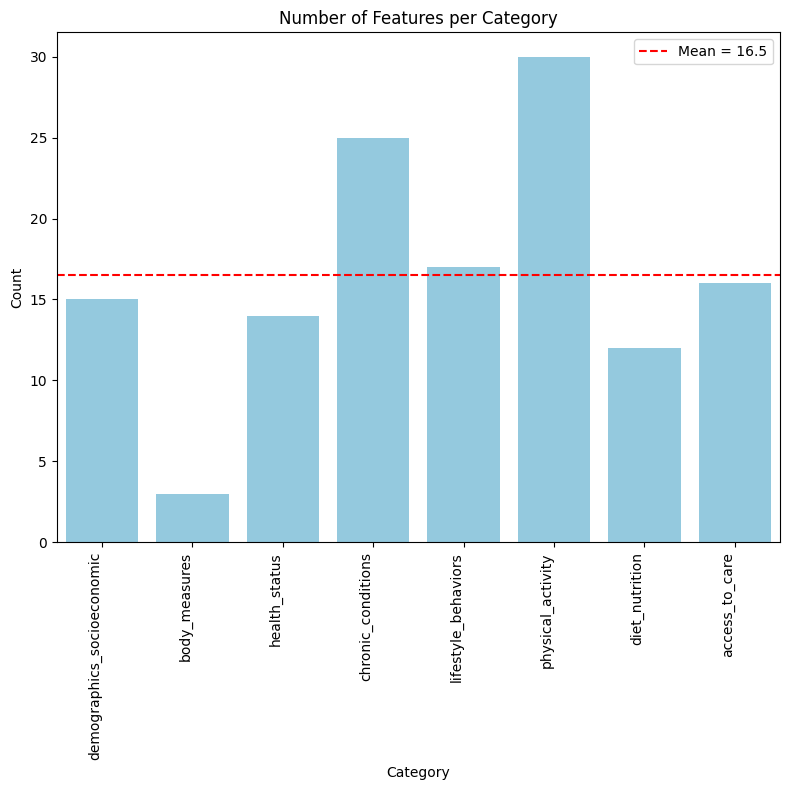

In [188]:
# number of features per category
category_counts = {cat: len(features) for cat, features in feature_clusters.items()}
cats = list(category_counts.keys())
counts = list(category_counts.values())
plot_path = os.path.join(plots_categories_dir, "features_per_category.png")

mean_val = np.mean(counts)
plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=counts, color="skyblue")
plt.axhline(mean_val, color="red", linestyle="--", label=f"Mean = {mean_val:.1f}")
plt.title("Number of Features per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Missing vals

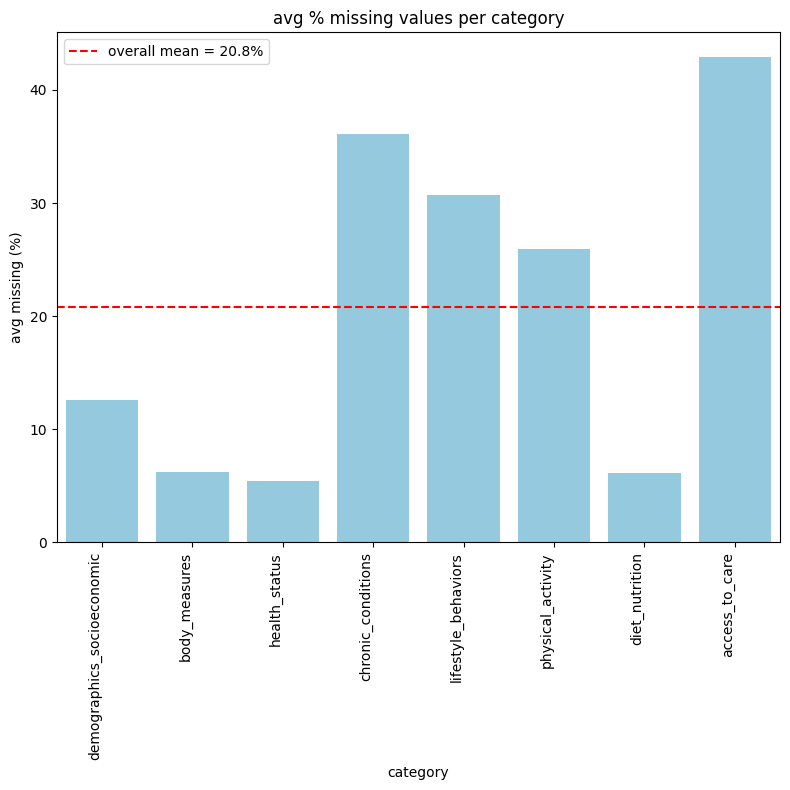

In [189]:
# % missing per var (reduced set)
missing_perc = np.mean(np.isnan(x_train_reduced), axis=0) * 100  
feature_to_cat = {f: c for c, feats in feature_clusters.items() for f in feats}

# group by category and avg
cat_missing = {
    c: np.mean([missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced])
    for c, feats in feature_clusters.items()
}

cats = list(cat_missing.keys())
avg_missing = list(cat_missing.values())


plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=avg_missing, color="skyblue")
plt.axhline(np.mean(avg_missing), color="red", ls="--",
            label=f"overall mean = {np.mean(avg_missing):.1f}%")
plt.title("avg % missing values per category")
plt.xlabel("category")
plt.ylabel("avg missing (%)")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_per_category.png"),
            dpi=300, bbox_inches="tight")
plt.show()


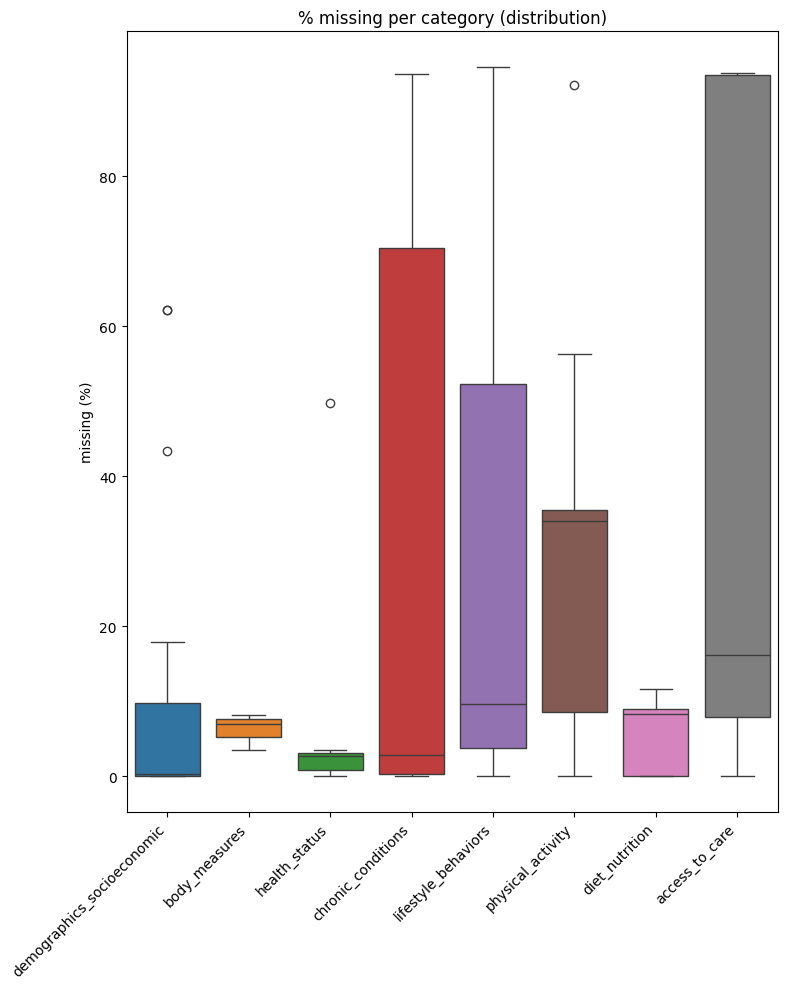

In [190]:
# boxplot of missing distrib per category
data_box = []
for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced]
    data_box.append(vals)

plt.figure(figsize=(8, 10))
sns.boxplot(data=data_box)
plt.xticks(ticks=range(len(cats)), labels=cats, rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing per category (distribution)")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_box.png"),
            dpi=300, bbox_inches="tight")
plt.show()


Missing value statistics per category

demographics_socioeconomic  mean=12.60%  std=22.44%  min= 0.00%  max=62.17%  median= 0.39%  iqr= 9.76%  >50%=2
body_measures              mean= 6.24%  std= 2.03%  min= 3.46%  max= 8.25%  median= 7.01%  iqr= 2.39%  >50%=0
health_status              mean= 5.43%  std=12.37%  min= 0.00%  max=49.80%  median= 2.69%  iqr= 2.35%  >50%=0
chronic_conditions         mean=36.12%  std=39.95%  min= 0.00%  max=93.64%  median= 2.89%  iqr=70.12%  >50%=11
lifestyle_behaviors        mean=30.72%  std=34.62%  min= 0.00%  max=94.58%  median= 9.64%  iqr=48.48%  >50%=7
physical_activity          mean=25.96%  std=21.01%  min= 0.00%  max=92.13%  median=33.99%  iqr=26.92%  >50%=3
diet_nutrition             mean= 6.12%  std= 4.42%  min= 0.00%  max=11.67%  median= 8.35%  iqr= 9.05%  >50%=0
access_to_care             mean=42.94%  std=41.06%  min= 0.00%  max=93.82%  median=16.16%  iqr=85.57%  >50%=7


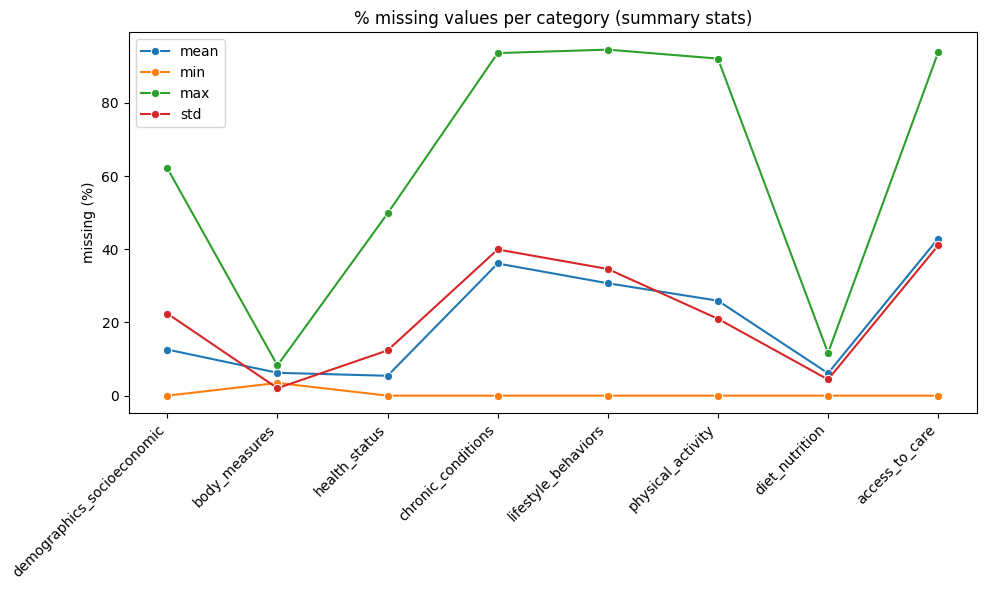

In [191]:
# % missing per feature
missing_perc = np.mean(np.isnan(x_train_reduced), axis=0) * 100

# compute stats per category
cat_names, mean_vals, std_vals, min_vals, max_vals = [], [], [], [], []
med_vals, iqr_vals, count_above_50 = [], [], []

for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced]
    if len(vals) == 0:
        continue
    vals = np.array(vals)
    cat_names.append(c)
    mean_vals.append(np.mean(vals))
    std_vals.append(np.std(vals))
    min_vals.append(np.min(vals))
    max_vals.append(np.max(vals))
    med_vals.append(np.median(vals))
    iqr_vals.append(np.percentile(vals, 75) - np.percentile(vals, 25))
    count_above_50.append(np.sum(vals > 50))

print("\nMissing value statistics per category\n")
for i, c in enumerate(cat_names):
    print(f"{c:25s}  mean={mean_vals[i]:5.2f}%  std={std_vals[i]:5.2f}%  "
          f"min={min_vals[i]:5.2f}%  max={max_vals[i]:5.2f}%  "
          f"median={med_vals[i]:5.2f}%  iqr={iqr_vals[i]:5.2f}%  "
          f">50%={int(count_above_50[i])}")

# plot mean/min/max/std
plt.figure(figsize=(10, 6))
sns.lineplot(x=cat_names, y=mean_vals, marker="o", label="mean")
sns.lineplot(x=cat_names, y=min_vals, marker="o", label="min")
sns.lineplot(x=cat_names, y=max_vals, marker="o", label="max")
sns.lineplot(x=cat_names, y=std_vals, marker="o", label="std")
plt.xticks(rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing values per category (summary stats)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## Correlation per category

In [192]:
len(feature_clusters)

8

### Plots

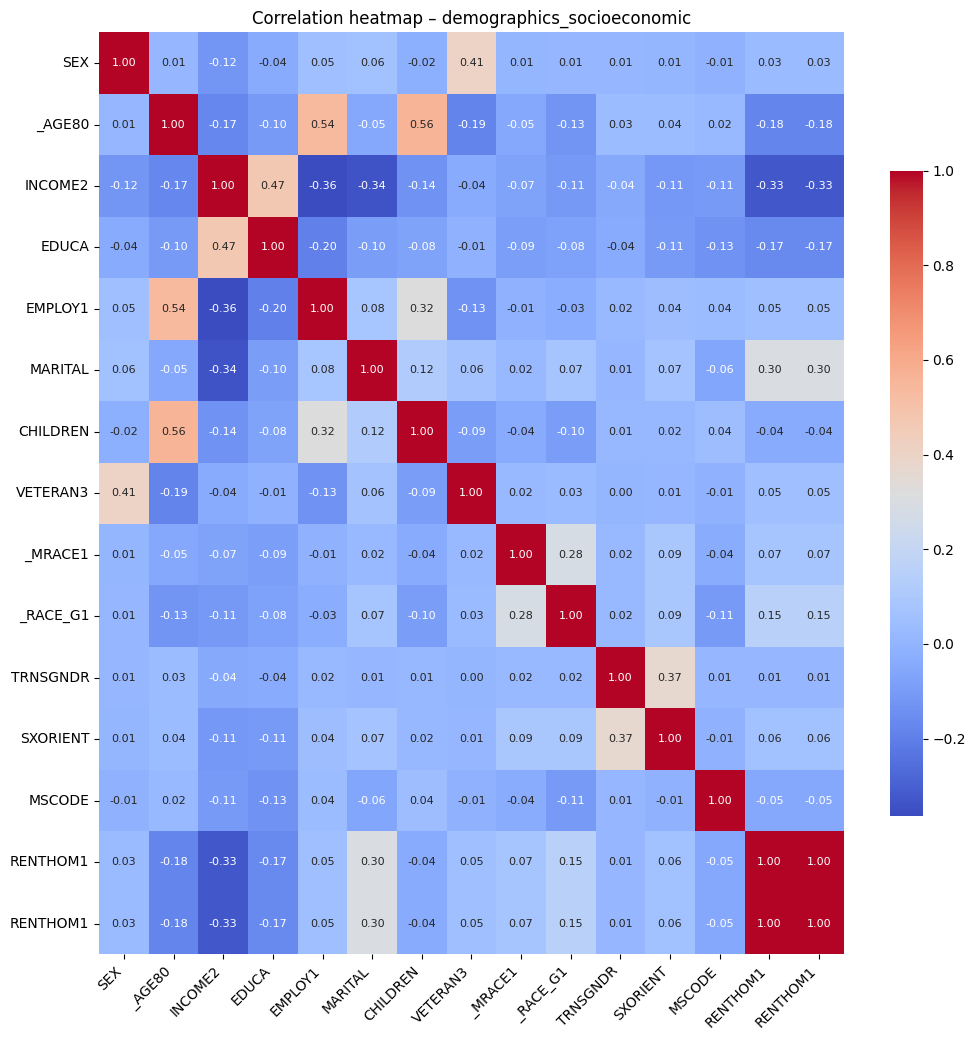

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_demographics_socioeconomic.png


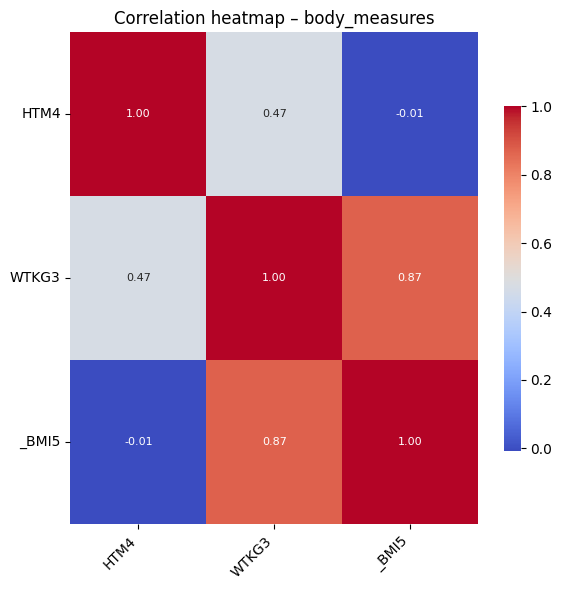

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_body_measures.png


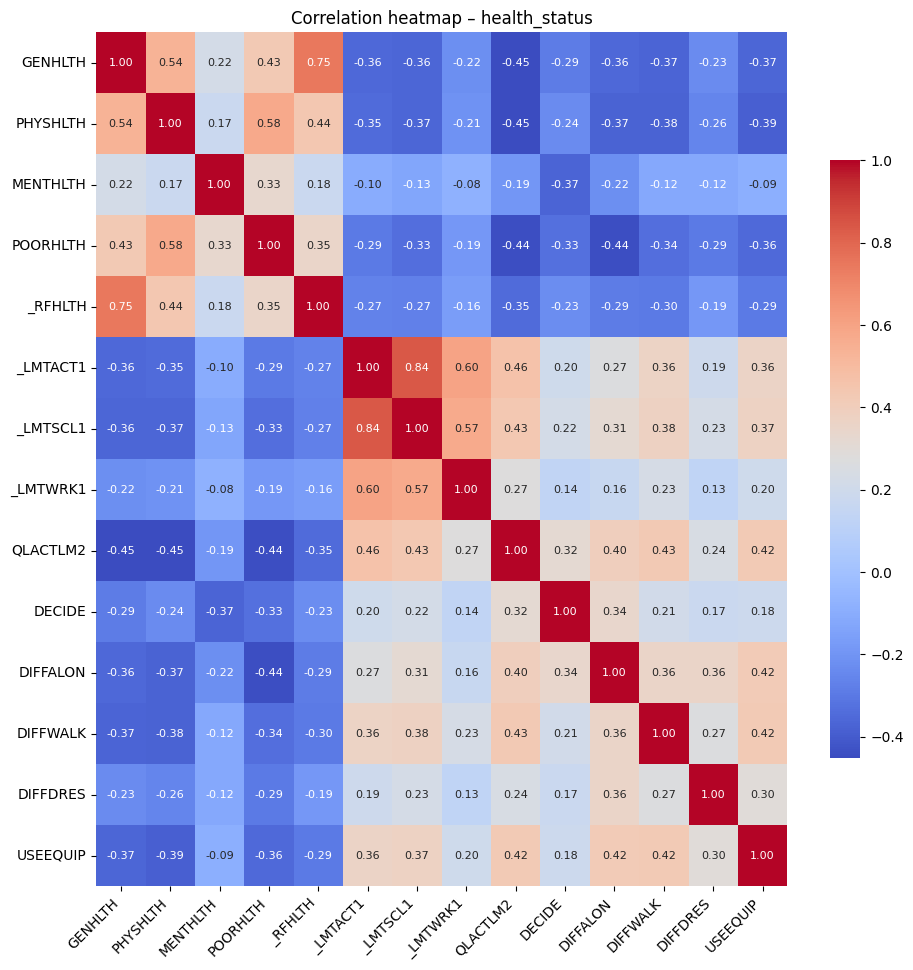

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_health_status.png


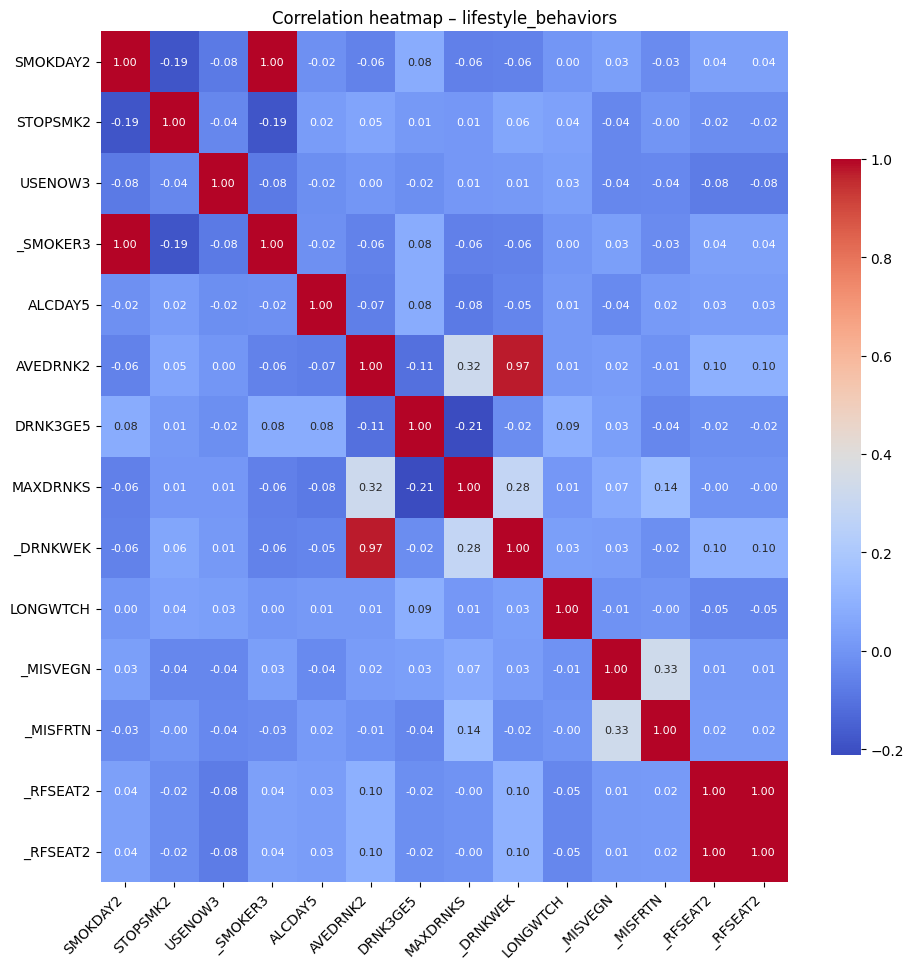

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_lifestyle_behaviors.png


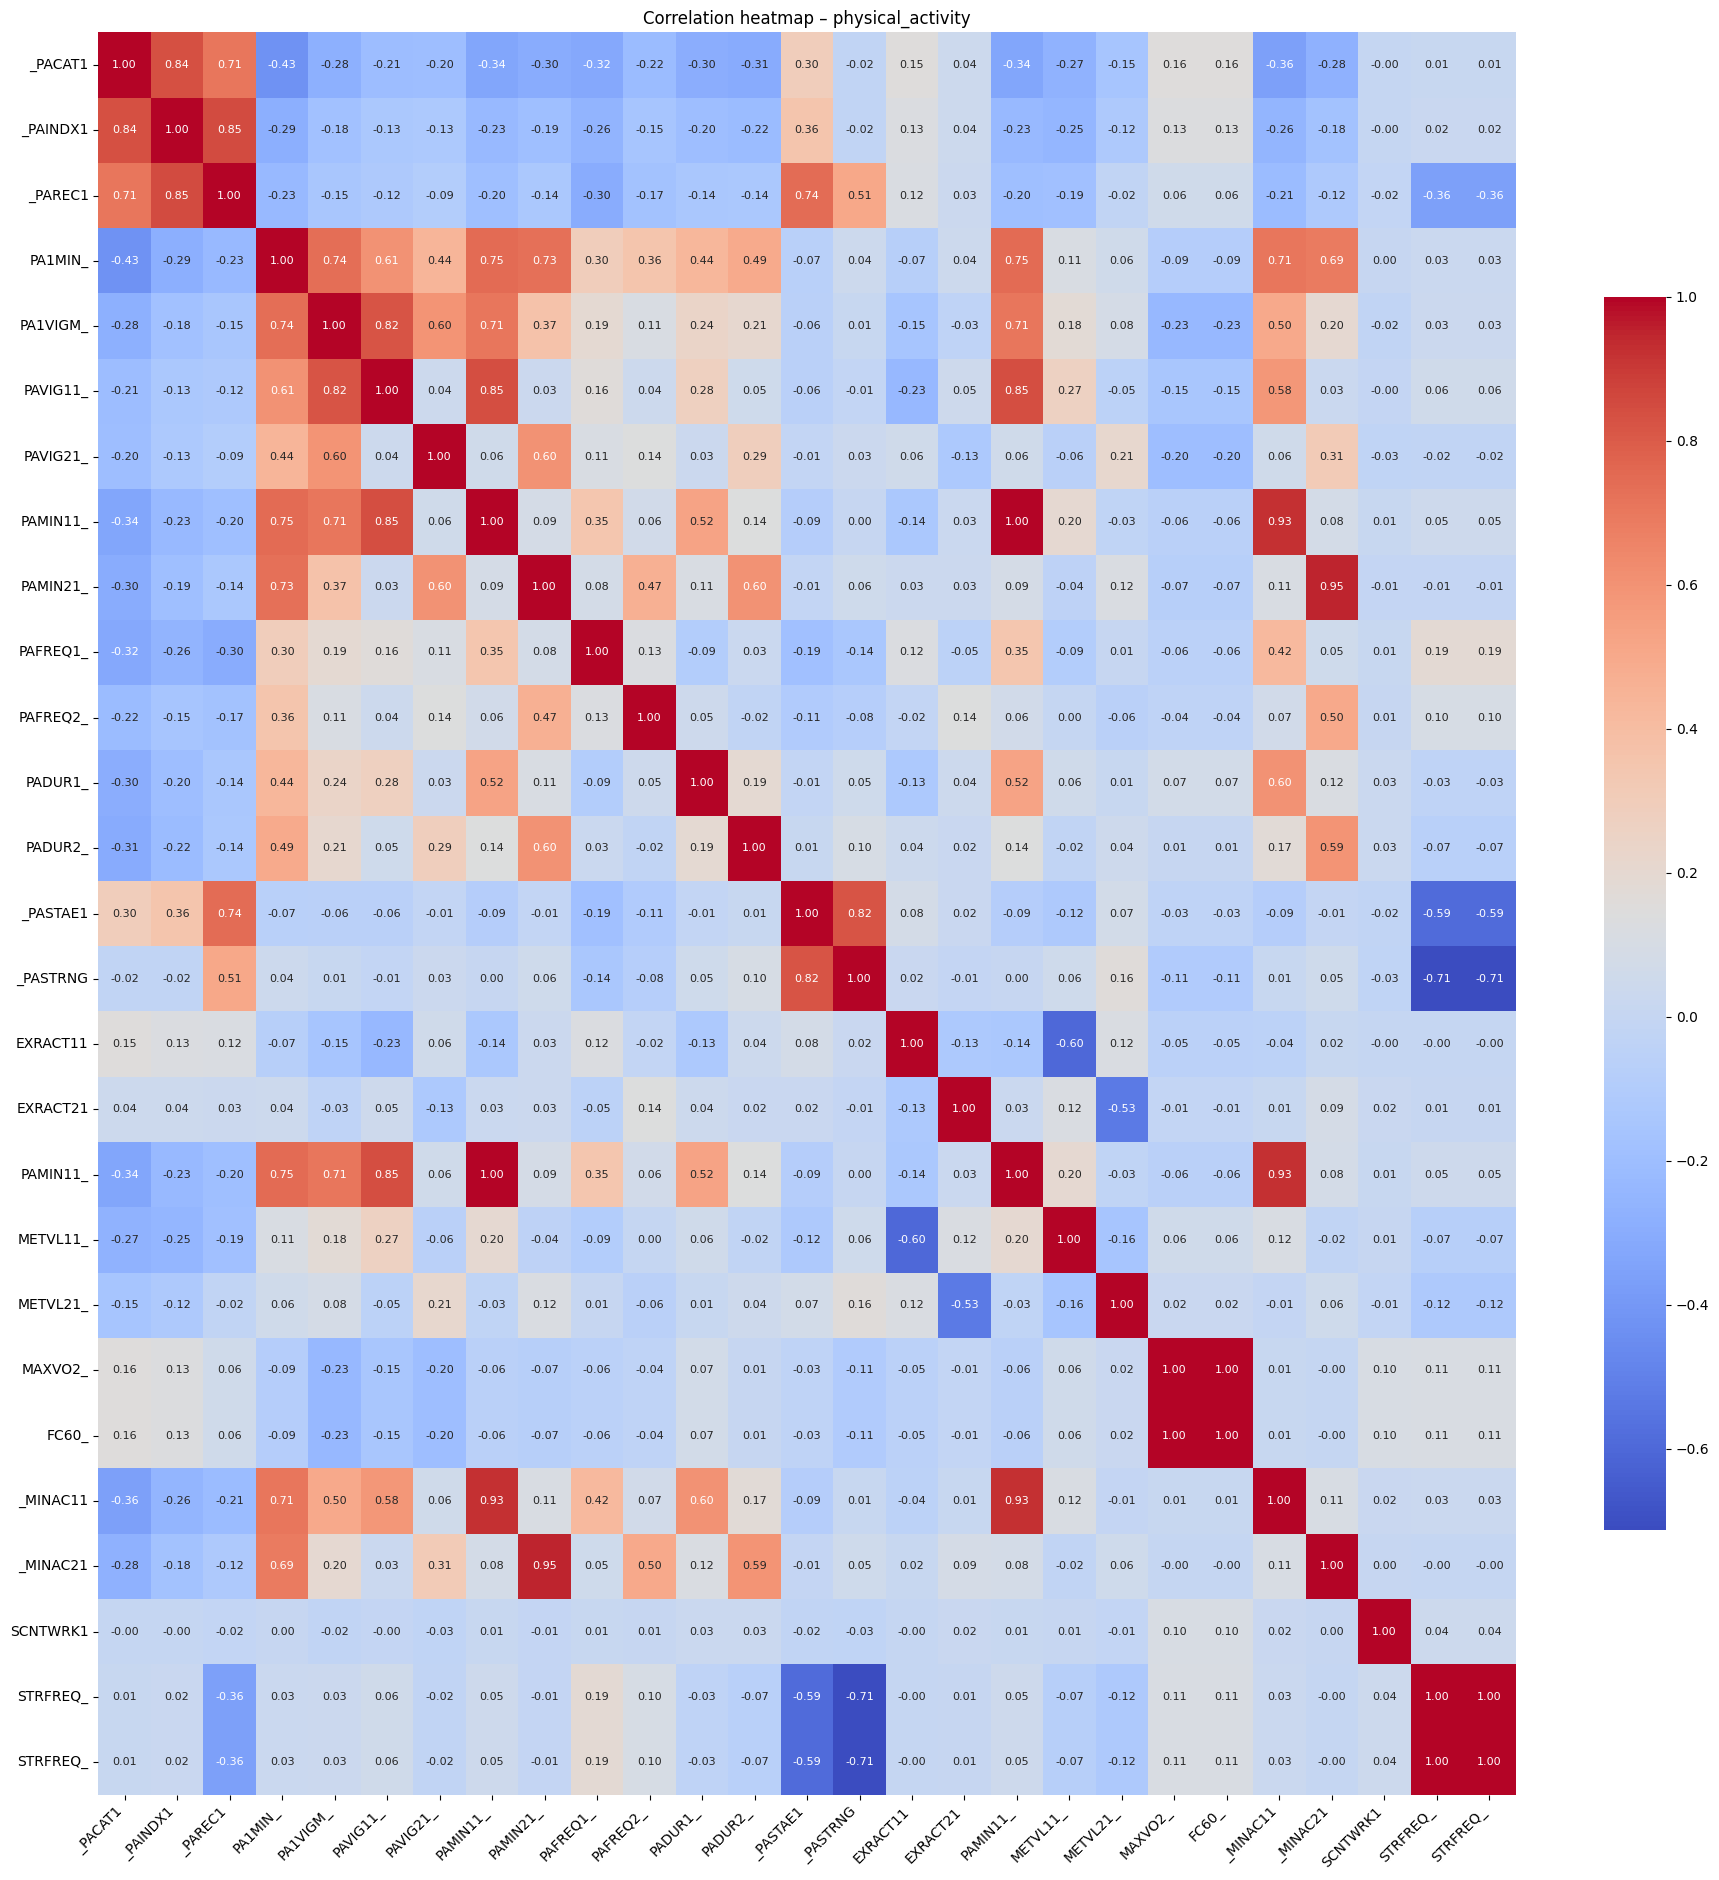

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_physical_activity.png


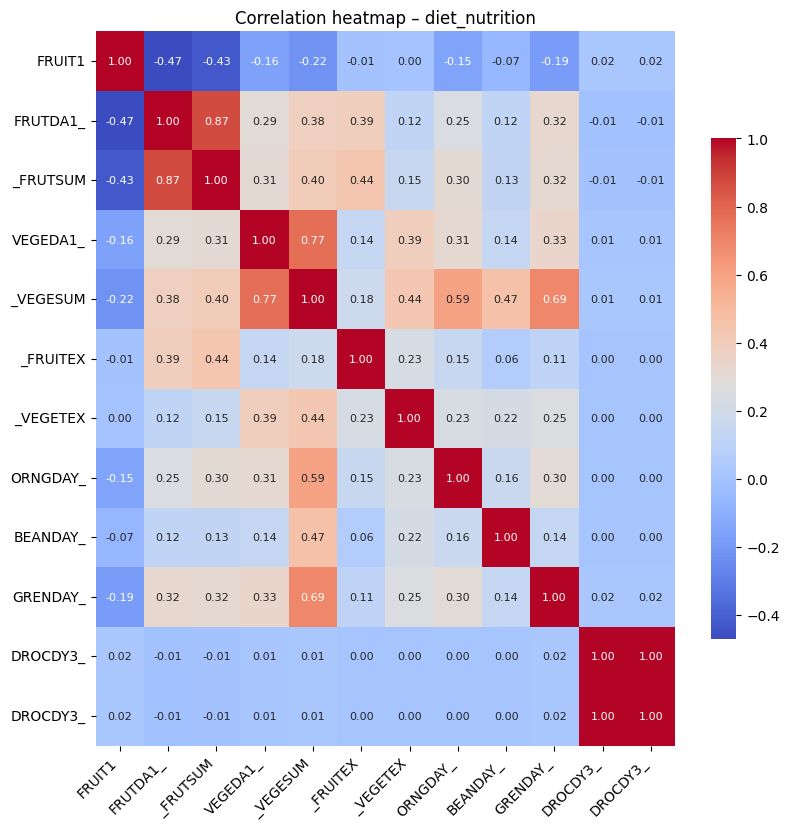

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_diet_nutrition.png


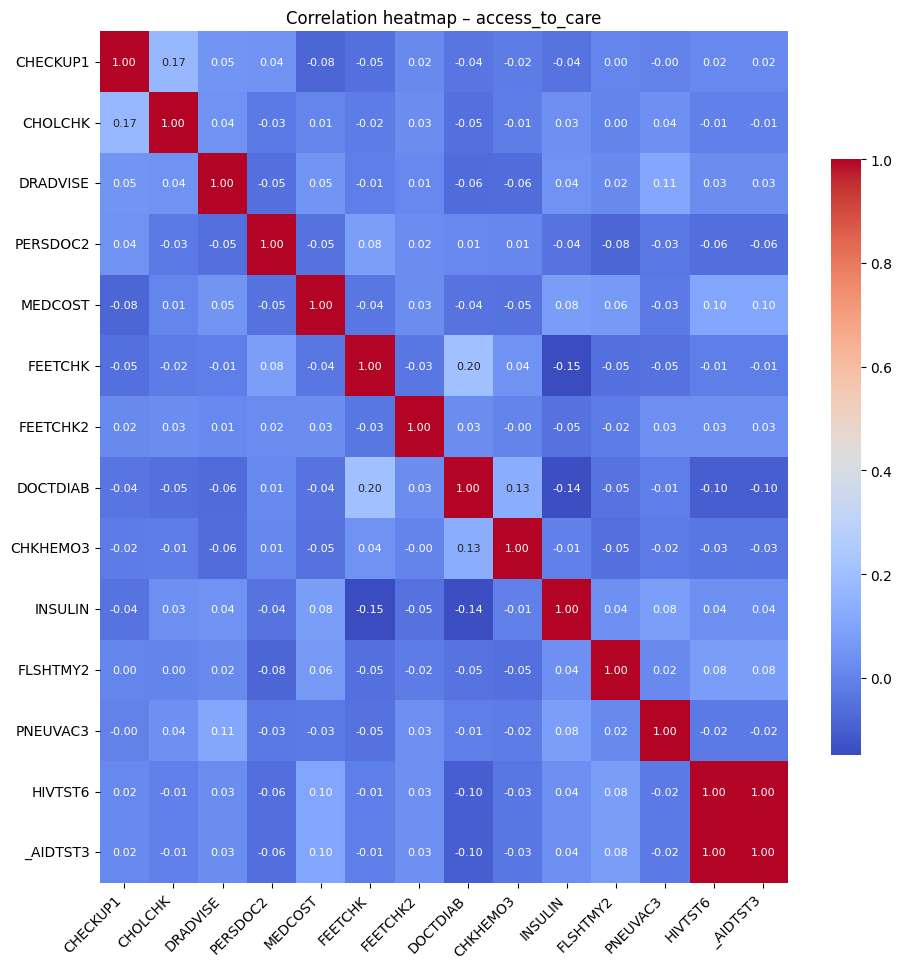

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_access_to_care.png


In [161]:
# folder for saving
cat_corr_dir = os.path.join(plots_dir, "categories", "corr")
os.makedirs(cat_corr_dir, exist_ok=True)

# loop over categories
for c, feats in feature_clusters.items():
    idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]
    if len(idxs) < 2:
        continue  # skip single-feature categories

    # subset data
    data_cat = x_train_reduced[:, idxs]

    # remove rows with NaN in any of these features
    mask = ~np.isnan(data_cat).any(axis=1)
    data_clean = data_cat[mask]

    # skip if too few valid rows
    if data_clean.shape[0] < 5:
        continue

    # drop constant cols (avoid zero std → divide by zero)
    stds = np.nanstd(data_clean, axis=0)
    valid_cols = stds > 0
    data_valid = data_clean[:, valid_cols]
    feats_valid = [f for f, keep in zip(feats, valid_cols) if keep]

    if data_valid.shape[1] < 2:
        print(f"Skipping {c}: not enough non-constant features.")
        continue

    # compute correlation
    corr = np.corrcoef(data_valid, rowvar=False)

    # dynamic color range for visibility
    vmin = np.nanmin(corr)
    vmax = np.nanmax(corr)
    if vmin == vmax:  # all identical
        vmin, vmax = -1, 1

    # plot size (scale with number of features)
    n = len(feats_valid)
    fig_size = max(6, 0.7 * n)
    plt.figure(figsize=(fig_size, fig_size))

    # create heatmap with annotations
    sns.heatmap(
        corr,
        vmin=vmin, vmax=vmax,
        cmap="coolwarm",
        annot=True, fmt=".2f", annot_kws={"size": 8},
        xticklabels=feats_valid, yticklabels=feats_valid,
        cbar_kws={"shrink": 0.7}
    )
    plt.title(f"Correlation heatmap – {c}")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # save + show
    save_path = os.path.join(cat_corr_dir, f"corr_{c}.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {save_path}")

In [193]:
# inspect variance & missingness per feature for chronic_conditions
target_cat = "chronic_conditions"
feats = feature_clusters[target_cat]
idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]

data_cat = x_train_reduced[:, idxs]
mask = ~np.isnan(data_cat).any(axis=1)
data_clean = data_cat[mask]

print(f"\n=== Category: {target_cat} ===")
print(f"Original features: {len(feats)}")
print(f"After dropping NaNs: {data_clean.shape[0]} samples remain\n")

for f, idx in zip(feats, idxs):
    vals = x_train_reduced[:, idx]
    non_missing = np.sum(~np.isnan(vals))
    unique_vals = np.unique(vals[~np.isnan(vals)])
    std = np.nanstd(vals)
    print(f"{f:15s} | non-missing={non_missing:5d} | unique={len(unique_vals):3d} | std={std:8.4f}")
    if len(unique_vals) <= 3:
        print(f"   values: {unique_vals}")

print("\nCheck if any column has zero variance:")
const_cols = [f for f, idx in zip(feats, idxs) if np.nanstd(x_train_reduced[:, idx]) == 0]
print(f"Constant columns: {const_cols if const_cols else 'None'}")



=== Category: chronic_conditions ===
Original features: 25
After dropping NaNs: 0 samples remain

_ASTHMS1        | non-missing=328135 | unique=  4 | std=  0.7904
_CASTHM1        | non-missing=328135 | unique=  3 | std=  0.7237
   values: [1. 2. 9.]
CHCCOPD1        | non-missing=326588 | unique=  2 | std=  0.2716
   values: [1. 2.]
CHCKIDNY        | non-missing=327158 | unique=  2 | std=  0.1841
   values: [1. 2.]
CHCSCNCR        | non-missing=328134 | unique=  4 | std=  0.3909
CHCOCNCR        | non-missing=328135 | unique=  4 | std=  0.3816
CVDSTRK3        | non-missing=328135 | unique=  4 | std=  0.3122
DIABETE3        | non-missing=328130 | unique=  6 | std=  0.7134
PREDIAB1        | non-missing=61232 | unique=  3 | std=  0.6136
   values: [1. 2. 3.]
DOCTDIAB        | non-missing=20950 | unique= 45 | std=  4.5584
DIABAGE2        | non-missing=41897 | unique= 96 | std= 18.0010
INSULIN         | non-missing=21710 | unique=  3 | std=  0.5243
   values: [1. 2. 9.]
FEETCHK         | non

- **Total features:** 25  
- **Complete rows:** 0 (after removing NaNs)

No single ROW in this category has valid (non NA) values accross all 25 features in this category simultaneously.

When computing the correlation matrix, we initially dropped any row containing a missing value.  Since different features are missing for different participants, this left **zero rows**, making correlation computation impossible.  


- **Variable characteristics:**  
  - Most features are **binary or small categorical codes** (`1/2`, sometimes `9` = missing/unknown).  
  - A few are **quantitative** (`DIABAGE2`, `DOCTDIAB`, `FEETCHK`, `FEETCHK2`) with high variability but very sparse coverage.  
  - None are constant - all have non-zero variance within their valid subsets.  
- **Missingness pattern:** highly unaligned - different variables are missing for different people, preventing any complete-case overlap.  
- **Consequence:** the default correlation method (`np.corrcoef` on complete rows) cannot compute correlations for this category.  
- **Fix / next step:**  
  - Use **pairwise correlation**, computing each pair’s correlation using only rows where both features are non-missing.  
  - This allows estimation of correlations even when full overlap across all features doesn’t exist.  
  - The resulting correlation matrix will contain some NaNs (where pairs have no valid overlap) but will still provide insight into variable relationships within the category.

In [194]:
def pairwise_corr_matrix(data):
    n = data.shape[1]
    corr = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(n):
            valid = ~np.isnan(data[:, i]) & ~np.isnan(data[:, j])
            if np.sum(valid) > 2:
                corr[i, j] = np.corrcoef(data[valid, i], data[valid, j])[0, 1]
    return corr


In [195]:
target_cat = "chronic_conditions"
feats = feature_clusters[target_cat]
idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]

data_cat = x_train_reduced[:, idxs]

c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


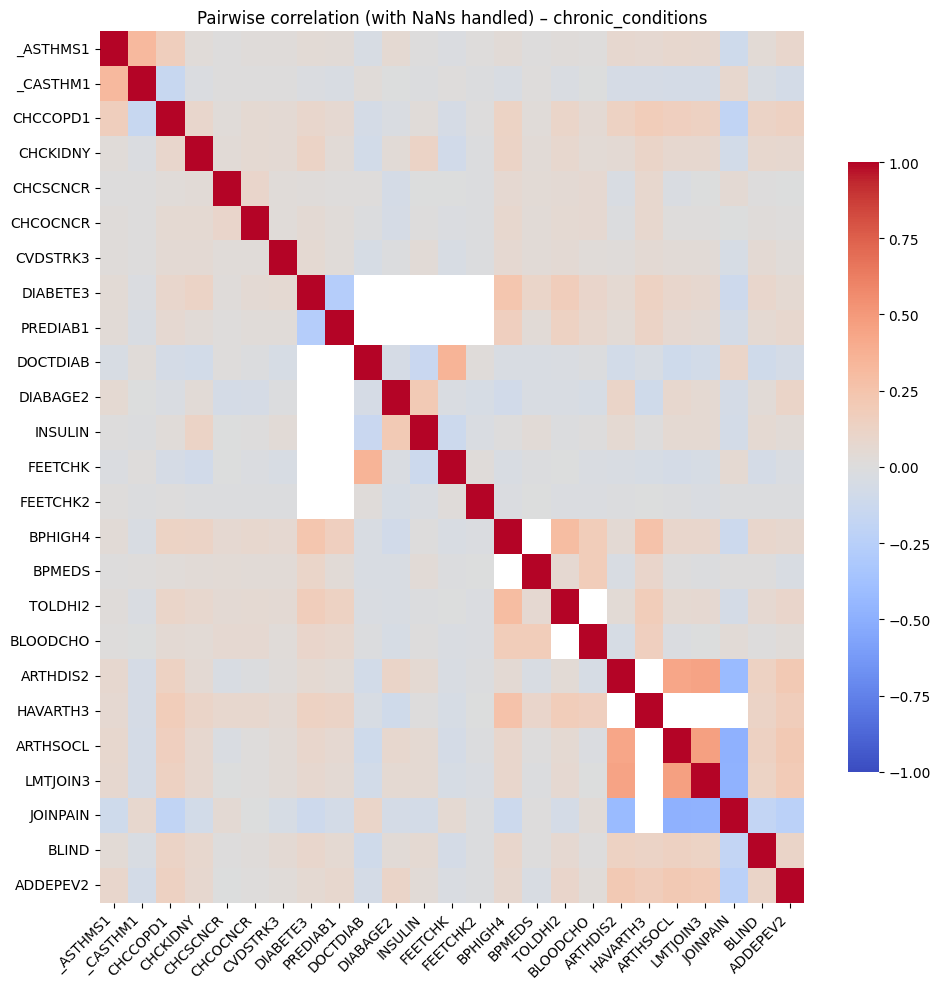

In [196]:
corr_pw = pairwise_corr_matrix(data_cat)

plt.figure(figsize=(10, 10))
sns.heatmap(
    corr_pw, vmin=-1, vmax=1, cmap="coolwarm",
    xticklabels=feats, yticklabels=feats,
    cbar_kws={"shrink": 0.7}, annot=False
)
plt.title("Pairwise correlation (with NaNs handled) – chronic_conditions")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
save_path = os.path.join(cat_corr_dir, f"corr_chronic_conditions.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [197]:
# print summary stats
num_valid = np.sum(~np.isnan(corr_pw))
print(f"Non-NaN correlations: {num_valid}/{corr_pw.size} ({100*num_valid/corr_pw.size:.1f}%)")

Non-NaN correlations: 593/625 (94.9%)


### Pairwise correlations

In [216]:
def compute_corr_pairs(X, names):
    """Compute pairwise correlations ignoring NaNs (no self corr)."""
    n = len(names)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            x_i, x_j = X[:, i], X[:, j]
            mask = ~np.isnan(x_i) & ~np.isnan(x_j)
            if mask.sum() > 1:
                r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
                pairs.append((names[i], names[j], r))
    return pairs


corr_thr = 0.6
top_k = 10
out_path = os.path.join(save_dir, "cluster_corr_summary.txt")

with open(out_path, "w", encoding="utf-8") as f:
    for cat, feats in feature_clusters.items():
        # keep only existing features
        valid_feats = [f for f in feats if f in reduced_feature_set]
        if len(valid_feats) < 2:
            msg = f"\n=== {cat.upper()} ===\nnot enough valid features\n"
            print(msg, end="")
            f.write(msg)
            continue

        # extract cols
        idx = [reduced_feature_set.index(f) for f in valid_feats]
        X = x_train_reduced[:, idx]

        # compute correlations
        pairs = compute_corr_pairs(X, valid_feats)
        if not pairs:
            msg = f"\n=== {cat.upper()} ===\nno valid pairs (all NaN)\n"
            print(msg, end="")
            f.write(msg)
            continue

        # sort and filter
        pairs.sort(key=lambda x: abs(x[2]), reverse=True)
        high_corr = [p for p in pairs if abs(p[2]) > corr_thr]
        top = pairs[:min(top_k, len(pairs))]

        # print results
        header = f"\n=== {cat.upper()} ===\n"
        stats = f"pairs |r| > {corr_thr}: {len(high_corr)}\n"
        print(header + stats, end="")
        f.write(header + stats)

        for a, b, r in top:
            line = f"{a:<15} <---->   {b:<15}  r={r:+.3f}\n"
            print(line, end="")
            f.write(line)


=== DEMOGRAPHICS_SOCIOECONOMIC ===
pairs |r| > 0.6: 1
RENTHOM1        <---->   RENTHOM1         r=+1.000
_AGE80          <---->   EMPLOY1          r=+0.488
_AGE80          <---->   CHILDREN         r=+0.476
TRNSGNDR        <---->   SXORIENT         r=+0.458
INCOME2         <---->   EDUCA            r=+0.452
MARITAL         <---->   RENTHOM1         r=+0.384
MARITAL         <---->   RENTHOM1         r=+0.384
_AGE80          <---->   RENTHOM1         r=-0.352
_AGE80          <---->   RENTHOM1         r=-0.352
INCOME2         <---->   EMPLOY1          r=-0.335

=== BODY_MEASURES ===
pairs |r| > 0.6: 1
WTKG3           <---->   _BMI5            r=+0.871
HTM4            <---->   WTKG3            r=+0.469
HTM4            <---->   _BMI5            r=-0.007

=== HEALTH_STATUS ===
pairs |r| > 0.6: 3
_LMTACT1        <---->   _LMTSCL1         r=+0.827
_LMTSCL1        <---->   _LMTWRK1         r=+0.785
GENHLTH         <---->   _RFHLTH          r=+0.681
_LMTACT1        <---->   _LMTWRK1         r=+

DEMOGRAPHICS_SOCIOECONOMIC
- Only one high correlation (|r| > 0.6): `RENTHOM1` with itself — irrelevant, ignore.
- Moderate correlations (0.4–0.5) among `_AGE80`, `EMPLOY1`, `CHILDREN`, `INCOME2`, `EDUCA`.
- These make sense socioeconomically (age ↔ employment, income ↔ education).
- No pair strong enough to justify dropping; keep all for now.


BODY_MEASURES
- Strong correlation: `WTKG3` ↔ `_BMI5` (r = 0.87).
- `BMI` is derived from height & weight → redundant.
- **Keep `_BMI5`** (standardized indicator), **drop `WTKG3`**.
- `HTM4` only weakly correlated, so keep it.


HEALTH_STATUS
- `_LMTACT1`, `_LMTSCL1`, `_LMTWRK1` are highly correlated (0.78–0.83).
- These likely represent limitations in activity, social, or work domains → overlapping.
- **Keep one representative**, e.g. `_LMTSCL1` (scale-type), drop `_LMTACT1` and `_LMTWRK1`.
- `GENHLTH` moderately correlated with `_RFHLTH` (r = 0.68); both measure general health → keep `GENHLTH`, drop `_RFHLTH`.



CHRONIC_CONDITIONS
- No high correlations (> 0.6).
- All |r| < 0.4 → independent enough.
- **Keep all features**.


LIFESTYLE_BEHAVIORS
- Perfect correlation `SMOKDAY2` ↔ `_SMOKER3` (r = 1.0) → identical info.
- `SMOKE100` ↔ `_SMOKER3` (r = 0.81) also high.
- Suggest **keep `_SMOKER3`** (cleaner aggregated flag) and **drop `SMOKDAY2`** and possibly `SMOKE100`.
- Others are weak → keep.


PHYSICAL_ACTIVITY
- Very high correlations:
  - `EXERANY2` ↔ `_TOTINDA` (r = 1.0)
  - `_PAREC1` ↔ `_PASTAE1` (r = 0.93)
- Both indicate identical or overlapping activity measures.
- **Drop `_TOTINDA`** (redundant with `EXERANY2`) and **drop `_PASTAE1`** (keep `_PAREC1`).
- Other pairs mostly NaN or moderate → keep.


DIET_NUTRITION
- High correlations:
  - `FRUTDA1_` ↔ `_FRUTSUM` (r = 0.88)
  - `VEGEDA1_` ↔ `_VEGESUM` (r = 0.77)
  - `_FRUITEX` ↔ `_VEGETEX` (r = 0.73)
  - `_VEGESUM` ↔ `GRENDAY_` (r = 0.70)
- Suggest **keep aggregate variables** (`_FRUTSUM`, `_VEGESUM`), **drop individual daily counts** (`FRUTDA1_`, `VEGEDA1_`).
- For `_FRUITEX` and `_VEGETEX`, both high and symmetric — keep one, e.g. `_FRUITEX`.



ACCESS_TO_CARE
- No strong correlations (> 0.6); top pair `CHECKUP1` ↔ `CHOLCHK` (r = 0.55).
- These reflect different preventive behaviors.
- **Keep all**; no redundancy.


In [222]:
corr_thr = 0.6
nan_info = {}
to_drop = set()

def nan_percent(x):
    return np.isnan(x).mean() * 100

print("=== Features flagged for high correlation (|r| > 0.6) ===")

for cat, feats in feature_clusters.items():
    valid_feats = [f for f in feats if f in reduced_feature_set]
    if len(valid_feats) < 2:
        continue

    idx = [reduced_feature_set.index(f) for f in valid_feats]
    X = x_train_reduced[:, idx]

    pairs = compute_corr_pairs(X, valid_feats)
    for a, b, r in pairs:
        if np.isnan(r) or abs(r) <= corr_thr:
            continue

        # compute NaN %
        nan_a = nan_percent(X[:, valid_feats.index(a)])
        nan_b = nan_percent(X[:, valid_feats.index(b)])

        # store for later
        nan_info[a] = nan_a
        nan_info[b] = nan_b

        # decide which to drop
        drop = a if nan_a > nan_b else b
        to_drop.add(drop)

        print(f"{a:<15} ({nan_a:5.2f}% NaN) <-> {b:<15} ({nan_b:5.2f}% NaN)  r={r:+.3f}  -> drop {drop}")

print("\n=== Suggested features to drop ===")
print(sorted(to_drop))


=== Features flagged for high correlation (|r| > 0.6) ===
RENTHOM1        ( 0.69% NaN) <-> RENTHOM1        ( 0.69% NaN)  r=+1.000  -> drop RENTHOM1
WTKG3           ( 7.01% NaN) <-> _BMI5           ( 8.25% NaN)  r=+0.871  -> drop _BMI5
GENHLTH         ( 0.00% NaN) <-> _RFHLTH         ( 0.00% NaN)  r=+0.681  -> drop GENHLTH
_LMTACT1        ( 3.49% NaN) <-> _LMTSCL1        ( 0.57% NaN)  r=+0.827  -> drop _LMTACT1
_LMTSCL1        ( 0.57% NaN) <-> _LMTWRK1        ( 0.57% NaN)  r=+0.785  -> drop _LMTWRK1


c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


SMOKE100        ( 3.95% NaN) <-> _SMOKER3        ( 4.04% NaN)  r=+0.813  -> drop _SMOKER3
SMOKDAY2        (58.32% NaN) <-> _SMOKER3        ( 4.04% NaN)  r=+1.000  -> drop SMOKDAY2
DRNKANY5        ( 0.00% NaN) <-> ALCDAY5         ( 4.87% NaN)  r=-0.936  -> drop ALCDAY5
DRNKANY5        ( 0.00% NaN) <-> _DRNKWEK        ( 0.00% NaN)  r=+0.852  -> drop _DRNKWEK
DRNKANY5        ( 0.00% NaN) <-> _MISVEGN        ( 0.00% NaN)  r=+0.602  -> drop _MISVEGN
DRNKANY5        ( 0.00% NaN) <-> _MISFRTN        ( 0.00% NaN)  r=+0.617  -> drop _MISFRTN
AVEDRNK2        (52.08% NaN) <-> _DRNKWEK        ( 0.00% NaN)  r=+0.980  -> drop AVEDRNK2
_DRNKWEK        ( 0.00% NaN) <-> _MISFRTN        ( 0.00% NaN)  r=+0.602  -> drop _MISFRTN
_MISVEGN        ( 0.00% NaN) <-> _MISFRTN        ( 0.00% NaN)  r=+0.901  -> drop _MISFRTN
_RFSEAT2        ( 9.64% NaN) <-> _RFSEAT2        ( 9.64% NaN)  r=+1.000  -> drop _RFSEAT2
EXERANY2        ( 8.55% NaN) <-> _TOTINDA        ( 8.55% NaN)  r=+1.000  -> drop _TOTINDA
_PACAT1    

In [262]:
to_drop = [
           "WTKG3", # body measures
           "_RFHLTH", "_LMTACT1", "_LMTWRK1", # health status
           "SMOKDAY2", "_SMOKER3", "AVEDRNK2", "ALCDAY5", "DRNK3GE5", "MAXDRNKS", "STOPSMK2", "WTCHSALT", "_MISFRTN", "_MISVEGN",  # lifestyle behaviors
           '_PASTAE1', '_TOTINDA', # physical activity
            'FRUTDA1_', 'VEGEDA1_', '_VEGETEX', 'GRENDAY_', '_FRUITEX', # diet & nutrition
            'HIVTST6' 
           ]


In [263]:
keep_mask = [f not in to_drop for f in reduced_feature_set]
x_train_final = x_train_reduced[:, keep_mask]
reduced_feature_set_final = [f for f in reduced_feature_set if f not in to_drop]
print(reduced_feature_set_final)

['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTRNG', 'EDUCA', 'CHCCOPD1', 'DRADVISE', 'CHCKIDNY', 'ARTHSOCL', '_RFSEAT2', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 'DIABAGE2', 'VETERAN3', 'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_PACAT1', 'INSULIN', 'DROCDY3_', 'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'RENTHOM1', 'PAMIN11_', 'PADUR2_', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 'POORHLTH', 'DIABETE3', '_FRUTSUM', 'PERSDOC2', 'STRFREQ_', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 'BPHIGH4', 'GENHLTH', 'EXRACT11', '_BMI5', 'PAVIG11_', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'ORNGDAY_', 'MSCODE', 'PHYSHLTH', 'TOLDHI2', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'CHCSCNCR', 'PAFREQ1_', '_AIDTST3', 'FLSHTMY2', 'PA1VIGM_', 'METVL21_', '_PAINDX1', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 'MAXVO2_', '_RACE_G1', '_MINAC11', 'LONGWTCH', 'FC60_', 'PAMISS1_', 'SCNTWRK1', 'FEETCHK2', 'EMPLOY1', 'BLOODCHO', 'USENOW3', 'PAMIN21_', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 'ADDEPEV2', '_AGE8

In [264]:
len(reduced_feature_set_final)

100

Repeat again to see if any high correlations left

In [292]:
# def compute_corr_pairs(X, names):
#     """Compute pairwise correlations ignoring NaNs (no self corr)."""
#     n = len(names)
#     pairs = []
#     for i in range(n):
#         for j in range(i + 1, n):
#             x_i, x_j = X[:, i], X[:, j]
#             mask = ~np.isnan(x_i) & ~np.isnan(x_j)
#             if mask.sum() > 1:
#                 r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
#                 pairs.append((names[i], names[j], r))
#     return pairs


def compute_corr_pairs(X, names, min_valid=100):
    """Pairwise correlation ignoring NaNs; skips pairs with too few valid points."""
    n = len(names)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            x_i, x_j = X[:, i], X[:, j]
            mask = ~np.isnan(x_i) & ~np.isnan(x_j)
            if mask.sum() < min_valid:
                continue  # too few valid values -> skip
            if np.std(x_i[mask]) == 0 or np.std(x_j[mask]) == 0:
                continue  # constant features -> undefined corr
            r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
            if not np.isnan(r):
                pairs.append((names[i], names[j], r))
    return pairs


corr_thr = 0.6
top_k = 31
out_path = os.path.join(save_dir, "cluster_corr_summary_second.txt")
to_drop_again = set()

with open(out_path, "w", encoding="utf-8") as f:
    # for cat, feats in feature_clusters.items() :
    for cat, feats in [('physical_activity', feature_clusters['physical_activity'])] :
        valid_feats = [f for f in feats if f in reduced_feature_set_final]
        if len(valid_feats) < 2:
            continue

        idx = [reduced_feature_set_final.index(f) for f in valid_feats]
        X = x_train_final[:, idx]

        pairs = compute_corr_pairs(X, valid_feats)
        for a, b, r in pairs:
            if np.isnan(r) or abs(r) <= corr_thr:
                continue

            # compute NaN %
            nan_a = nan_percent(X[:, valid_feats.index(a)])
            nan_b = nan_percent(X[:, valid_feats.index(b)])

            # store for later
            nan_info[a] = nan_a
            nan_info[b] = nan_b

            # decide which to drop
            drop = a if nan_a > nan_b else b
            to_drop_again.add(drop)

            print(f"{a:<15} ({nan_a:5.2f}% NaN) <-> {b:<15} ({nan_b:5.2f}% NaN)  r={r:+.3f}  -> drop {drop}")

    print("\n=== Suggested features to drop ===")
    print(sorted(to_drop_again))

_PACAT1         ( 0.00% NaN) <-> _PAINDX1        ( 0.00% NaN)  r=+0.923  -> drop _PAINDX1
_PACAT1         ( 0.00% NaN) <-> _PAREC1         ( 0.00% NaN)  r=+0.914  -> drop _PAREC1
_PACAT1         ( 0.00% NaN) <-> PAMISS1_        ( 0.00% NaN)  r=+0.749  -> drop PAMISS1_
_PAINDX1        ( 0.00% NaN) <-> _PAREC1         ( 0.00% NaN)  r=+0.914  -> drop _PAREC1
_PAINDX1        ( 0.00% NaN) <-> PAMISS1_        ( 0.00% NaN)  r=+0.848  -> drop PAMISS1_
_PAREC1         ( 0.00% NaN) <-> PAMISS1_        ( 0.00% NaN)  r=+0.735  -> drop PAMISS1_
PA1MIN_         (34.39% NaN) <-> PA1VIGM_        (34.07% NaN)  r=+0.790  -> drop PA1MIN_
PA1MIN_         (34.39% NaN) <-> PAVIG11_        (34.68% NaN)  r=+0.623  -> drop PAVIG11_
PA1MIN_         (34.39% NaN) <-> PAMIN11_        (35.76% NaN)  r=+0.776  -> drop PAMIN11_
PA1MIN_         (34.39% NaN) <-> PAMIN21_        (36.27% NaN)  r=+0.727  -> drop PAMIN21_
PA1MIN_         (34.39% NaN) <-> PAMIN11_        (35.76% NaN)  r=+0.776  -> drop PAMIN11_
PA1MIN_      

In [293]:
vars_to_check = [
    "EXERANY2", "PA1MIN_", "PAVIG11_", "PA1VIGM_",
    "PAVIG21_", "PAMIN11_", "MAXVO2_", "FC60_", "_MINAC21"
]

for var in vars_to_check:
    idx = reduced_feature_set_final.index(var)
    na_pct = np.isnan(x_train_final[:, idx]).mean() * 100
    print(f"{var:<10}: {na_pct:6.4f}% NaN")


EXERANY2  : 8.5535% NaN
PA1MIN_   : 34.3941% NaN
PAVIG11_  : 34.6763% NaN
PA1VIGM_  : 34.0692% NaN
PAVIG21_  : 35.6597% NaN
PAMIN11_  : 35.7642% NaN
MAXVO2_   : 0.0000% NaN
FC60_     : 0.0000% NaN
_MINAC21  : 35.6015% NaN
